title: "Is the smog forecast right in my city? 27 cities, checked every day"
date: "2026-11-15"
summary: "I compare the Copernicus (CAMS) fine-dust forecast with official stations in 27 European cities. The yardstick is the simplest forecast there is: tomorrow will be like today. The raw forecast clearly wins in 9 cities and clearly loses in 7. A small correction learned from each station beats the rule in all 27."
tags: [CAMS, Copernicus, PM2.5, Forecast verification, Validation]
project: air-check

**Question:** the Copernicus Atmosphere Monitoring Service (CAMS) forecasts fine dust (PM2.5) for all of Europe
every day. Is this forecast good in my city?

**The yardstick:** the simplest forecast there is, called *persistence*: "tomorrow will be like today".
A forecast is useful in a city only if it beats this rule.

**Data:**
- measurements: one official urban background station per city, from the European Environment Agency (EEA);
- forecast: the CAMS ensemble (about 10 km grid), daily mean at the station location;
- 27 cities in 6 countries: Poland, Italy, France, Switzerland, Sweden and Finland.

**How it works:** a small pipeline called [Air Check](https://github.com/geoworldlook/air-check) runs every morning
without a person. It saves the new forecast, compares the old forecast with what the stations measured, and
updates a [live panel](https://geoworldlook.github.io/air-check/showcase/aircheck_panel.html).

All numbers below come from the published result of the pipeline. This post is a snapshot; the panel is always current.

In [1]:
#| include: false
import json, urllib.request
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from IPython.display import Markdown, HTML, display

URL = "https://geoworldlook.github.io/air-check/showcase/aircheck_data.json"
local = Path("../docs/showcase/aircheck_data.json")
try:
    D = json.load(urllib.request.urlopen(URL, timeout=60))
except Exception:
    D = json.loads(local.read_text(encoding="utf-8"))
S = D["stations"]
COL = {"better": "#2f7a45", "similar": "#8a8f88", "worse": "#b23a2e", "insufficient": "#cfd3cc"}
rows = []
for s in S:
    a, w = s["archive_365"], s["archive_winter"]
    rows.append(dict(city=s["city"], country=s["country"], n=a.get("n", 0), rmse_fc=a.get("rmse_fc"), rmse_pers=a.get("rmse_pers"),
                     skill=a.get("skill"), lo=a["skill_ci"][0], hi=a["skill_ci"][1], verdict=a["verdict"], bias=a.get("bias"),
                     winter_bias=w.get("bias"), exceed=a.get("exceed_days", 0), hits=a.get("hits", 0), misses=a.get("misses", 0),
                     false_alarms=a.get("false_alarms", 0), csi_fc=a.get("csi_fc"), csi_pers=a.get("csi_pers")))
T = pd.DataFrame(rows)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})

## 1. How much data we have

In [2]:
#| echo: false
n = T["verdict"].value_counts()
display(Markdown(
    f"- **{len(T)} cities**, about **{int(T['n'].min())}–{int(T['n'].max())} compared days** per city in the last 365 days "
    f"(to {D['run_date']}).\n"
    f"- Each day gives one pair: the daily mean PM2.5 measured at the station and the daily mean that was forecast.\n"
    f"- The forecasts in this section come from the forecast archive. Their lead time is below one day, "
    f"so they are a little easier than a true day-ahead forecast.\n"
    f"- The measurements start in 2022. Forecasts can be checked only from November 2023, where the archive starts."))

- **27 cities**, about **304–365 compared days** per city in the last 365 days (to 2026-11-17).
- Each day gives one pair: the daily mean PM2.5 measured at the station and the daily mean that was forecast.
- The forecasts in this section come from the forecast archive. Their lead time is below one day, so they are a little easier than a true day-ahead forecast.
- The measurements start in 2022. Forecasts can be checked only from November 2023, where the archive starts.

## 2. Does the forecast beat "tomorrow = today"?

For each city I compute the typical error (RMSE) of the forecast and of the rule "tomorrow = today".
The **skill score** puts both into one number: 1 − (forecast error ÷ rule error)².

- above 0: the forecast is better than the rule;
- below 0: the rule is better;
- the line shows the 95% interval. I give a verdict only when the whole interval is on one side of 0.

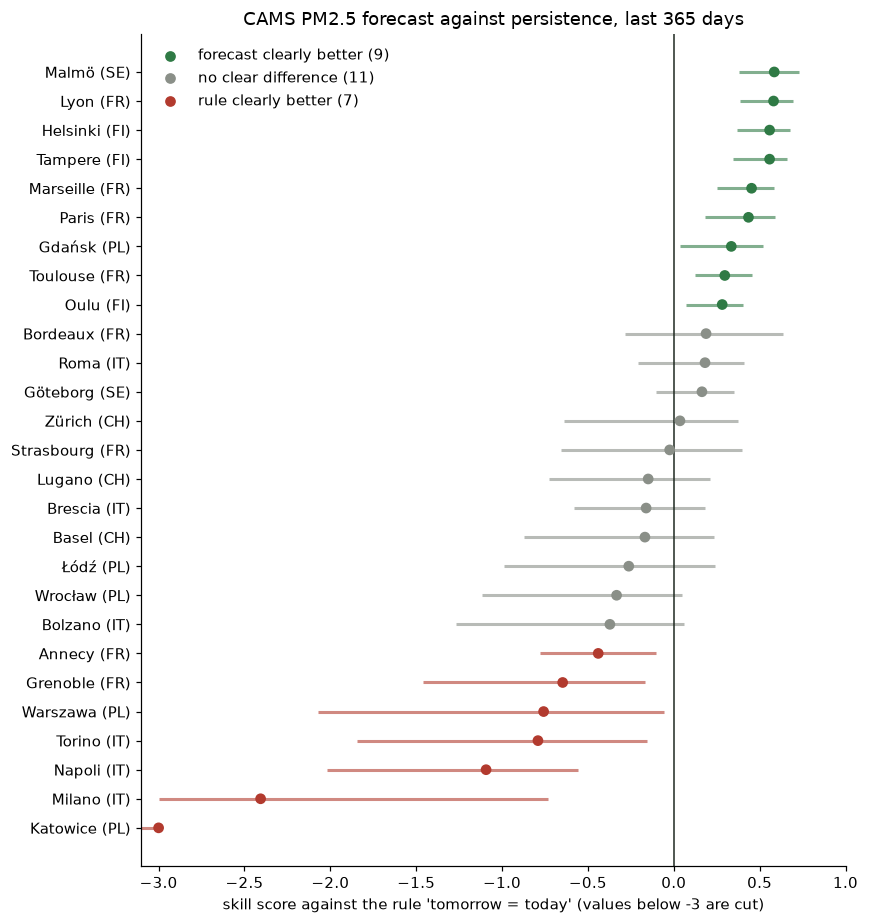

In [3]:
#| echo: false
t = T.sort_values("skill")
fig, ax = plt.subplots(figsize=(8, 8.5))
y = np.arange(len(t))
lo = np.clip(t["lo"].to_numpy(float), -3, None); sk = np.clip(t["skill"].to_numpy(float), -3, None)
ax.hlines(y, lo, t["hi"], color=[COL[v] for v in t["verdict"]], lw=2, alpha=0.6)
ax.scatter(sk, y, color=[COL[v] for v in t["verdict"]], zorder=3, s=36)
ax.axvline(0, color="#1f2a22", lw=1)
ax.set_yticks(y); ax.set_yticklabels([f"{c} ({k})" for c, k in zip(t["city"], t["country"])])
ax.set_xlim(-3.1, 1); ax.set_xlabel("skill score against the rule 'tomorrow = today' (values below -3 are cut)")
for v, lab in (("better", "forecast clearly better"), ("similar", "no clear difference"), ("worse", "rule clearly better")):
    ax.scatter([], [], color=COL[v], label=f"{lab} ({int((T['verdict'] == v).sum())})")
ax.legend(loc="upper left", frameon=False)
ax.set_title("CAMS PM2.5 forecast against persistence, last 365 days")
plt.tight_layout(); plt.show()

In [4]:
#| echo: false
b = ", ".join(T[T["verdict"] == "better"].sort_values("skill", ascending=False)["city"])
w = ", ".join(T[T["verdict"] == "worse"].sort_values("skill")["city"])
display(Markdown(
    f"**Result:** the forecast is clearly better in **{int((T['verdict'] == 'better').sum())} of {len(T)} cities** ({b}). "
    f"The simple rule is clearly better in **{int((T['verdict'] == 'worse').sum())}** ({w}). "
    f"In the other {int((T['verdict'] == 'similar').sum())} cities there is no clear difference."))

**Result:** the forecast is clearly better in **9 of 27 cities** (Malmö, Lyon, Helsinki, Tampere, Marseille, Paris, Gdańsk, Toulouse, Oulu). The simple rule is clearly better in **7** (Katowice, Milano, Napoli, Torino, Warszawa, Grenoble, Annecy). In the other 11 cities there is no clear difference.

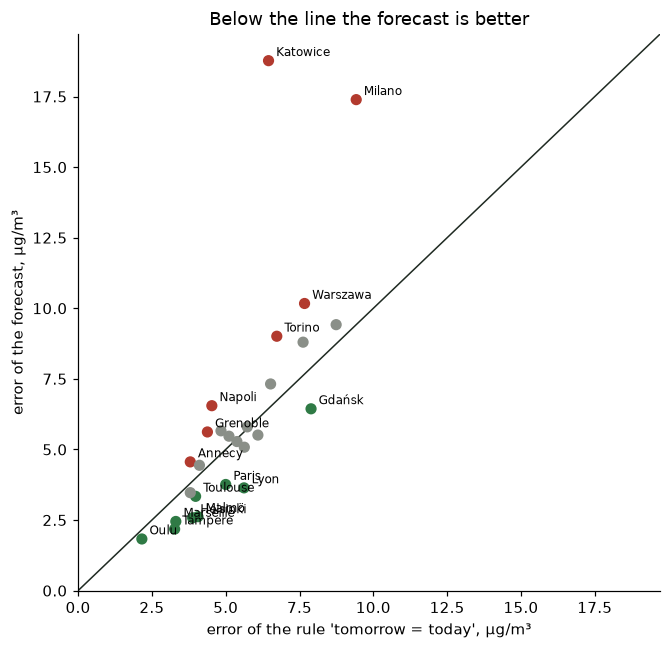

In [5]:
#| echo: false
fig, ax = plt.subplots(figsize=(6.2, 6))
m = float(np.nanmax([T["rmse_fc"].max(), T["rmse_pers"].max()])) * 1.05
ax.plot([0, m], [0, m], color="#1f2a22", lw=1)
ax.scatter(T["rmse_pers"], T["rmse_fc"], color=[COL[v] for v in T["verdict"]], s=40, zorder=3)
for _, r in T.iterrows():
    if r["verdict"] != "similar":
        ax.annotate(r["city"], (r["rmse_pers"], r["rmse_fc"]), textcoords="offset points", xytext=(5, 3), fontsize=8)
ax.set_xlim(0, m); ax.set_ylim(0, m)
ax.set_xlabel("error of the rule 'tomorrow = today', µg/m³"); ax.set_ylabel("error of the forecast, µg/m³")
ax.set_title("Below the line the forecast is better")
plt.tight_layout(); plt.show()

## 3. Two cities: one where the forecast works and one where it does not

The black line is the measurement, the blue line is the forecast. The dashed red line marks 25 µg/m³,
my threshold for a "high-dust day".

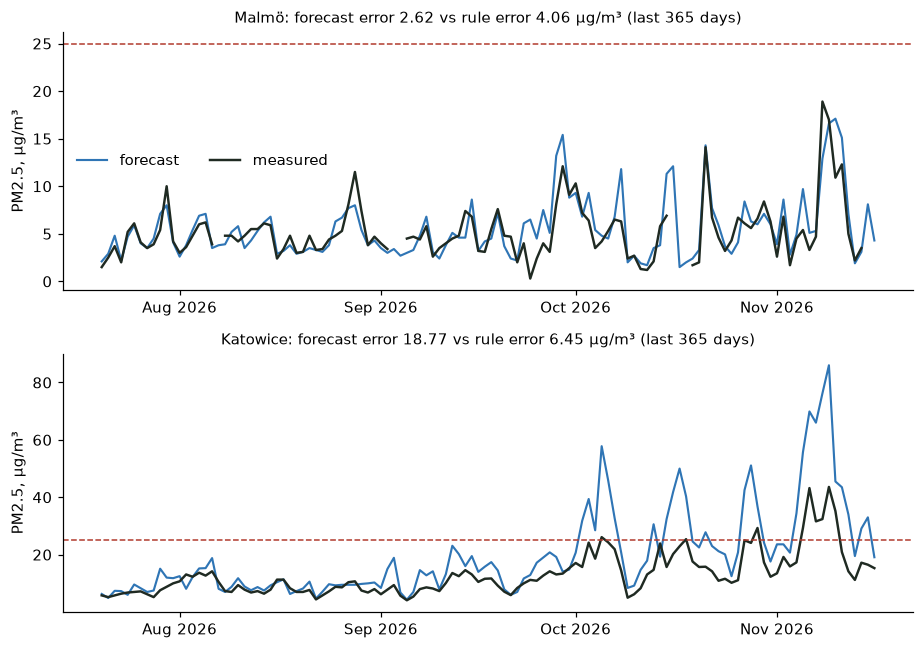

In [6]:
#| echo: false
best = T[T["verdict"] == "better"].sort_values("skill").iloc[-1]["city"]
worst = T[T["verdict"] == "worse"].sort_values("skill").iloc[0]["city"]
fig, axes = plt.subplots(2, 1, figsize=(8.5, 6), sharex=False)
for ax, city in zip(axes, (best, worst)):
    s = next(x for x in S if x["city"] == city); c = s["chart"]; a = s["archive_365"]
    d = pd.to_datetime(c["dates"])
    ax.plot(d, pd.Series(c["fc"], dtype=float), color="#2f75b5", lw=1.4, label="forecast")
    ax.plot(d, pd.Series(c["obs"], dtype=float), color="#1f2a22", lw=1.6, label="measured")
    ax.axhline(D["threshold"], color="#b23a2e", ls="--", lw=1)
    ax.set_title(f"{city}: forecast error {a['rmse_fc']} vs rule error {a['rmse_pers']} µg/m³ (last 365 days)", fontsize=10)
    ax.set_ylabel("PM2.5, µg/m³")
    ax.xaxis.set_major_locator(mdates.MonthLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
axes[0].legend(frameon=False, ncol=2)
plt.tight_layout(); plt.show()

## 4. Where the forecast is too high in winter

In several cities the forecast is much higher than the measurement in the cold months (November to March).
This is the main reason why the simple rule wins there.

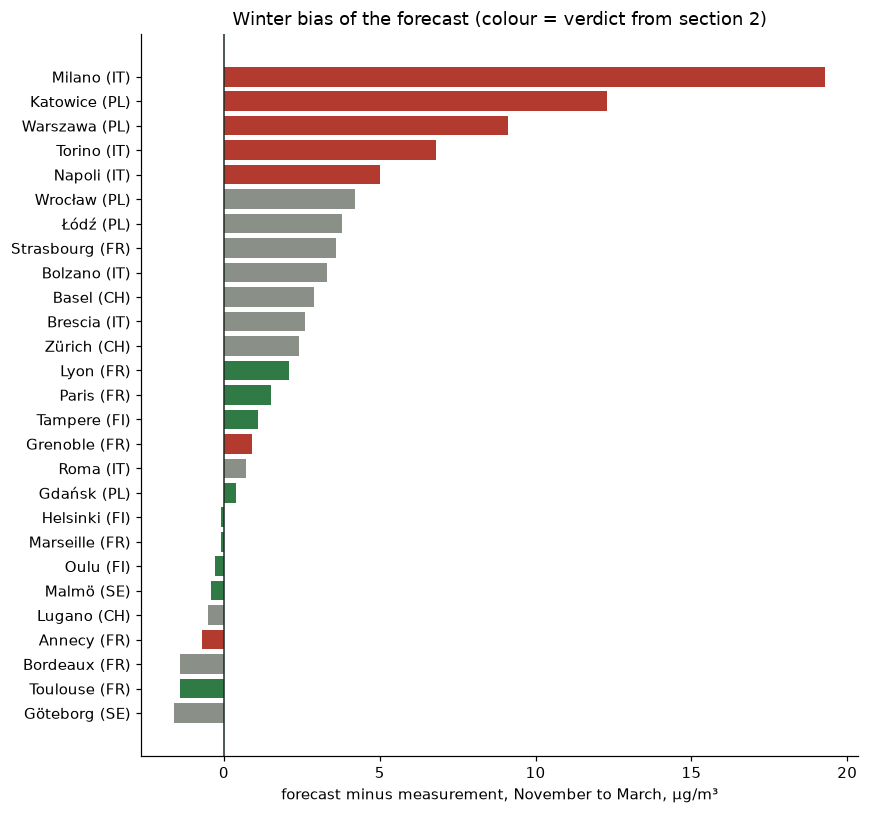

Largest winter over-forecast: **Milano +19.3**, **Katowice +12.3**, **Warszawa +9.1**, **Torino +6.8** µg/m³. I did not investigate the cause. I report it as measured.

In [7]:
#| echo: false
t = T.dropna(subset=["winter_bias"]).sort_values("winter_bias")
fig, ax = plt.subplots(figsize=(8, 7.5))
ax.barh([f"{c} ({k})" for c, k in zip(t["city"], t["country"])], t["winter_bias"], color=[COL[v] for v in t["verdict"]])
ax.axvline(0, color="#1f2a22", lw=1)
ax.set_xlabel("forecast minus measurement, November to March, µg/m³")
ax.set_title("Winter bias of the forecast (colour = verdict from section 2)")
plt.tight_layout(); plt.show()
top = t.sort_values("winter_bias", ascending=False).head(4)
display(Markdown("Largest winter over-forecast: " + ", ".join(f"**{r.city} +{r.winter_bias:.1f}**" for r in top.itertuples()) +
                 " µg/m³. I did not investigate the cause. I report it as measured."))

## 5. High-dust days

For a resident the important question is simple: does the forecast warn me before a day with a lot of dust?
A day counts as "high" when the measured daily mean is above 25 µg/m³. The **hit score** is hits ÷ (hits + misses + false alarms).
The table shows cities with at least 20 such days.

In [8]:
#| echo: false
t = T[T["exceed"] >= 20].sort_values("exceed", ascending=False)
out = t[["city", "country", "exceed", "hits", "misses", "false_alarms", "csi_fc", "csi_pers"]].rename(columns={
    "city": "City", "country": "Country", "exceed": "High-dust days", "hits": "Forecast hits", "misses": "Missed",
    "false_alarms": "False alarms", "csi_fc": "Hit score: forecast", "csi_pers": "Hit score: rule"})
display(HTML(out.to_html(index=False, border=0)))
k = int((t["csi_fc"] > t["csi_pers"]).sum())
display(Markdown(f"The forecast has the higher hit score in **{k} of {len(t)}** of these cities. "
                 f"In the others the rule 'tomorrow = today' catches high-dust days equally well or better."))

City,Country,High-dust days,Forecast hits,Missed,False alarms,Hit score: forecast,Hit score: rule
Brescia,IT,91,84,7,28,0.71,0.65
Wrocław,PL,81,65,16,28,0.60,0.60
Milano,IT,76,76,0,68,0.53,0.65
Łódź,PL,72,54,18,36,0.50,0.50
Katowice,PL,62,62,0,68,0.48,0.48
Torino,IT,60,55,5,40,0.55,0.50
Gdańsk,PL,52,42,10,13,0.65,0.49
Warszawa,PL,46,39,7,47,0.42,0.48
Roma,IT,24,18,6,19,0.42,0.33
Strasbourg,FR,22,13,9,23,0.29,0.22


The forecast has the higher hit score in **6 of 11** of these cities. In the others the rule 'tomorrow = today' catches high-dust days equally well or better.

## 6. Can the forecast be fixed? A small correction for each station

The winter error from section 4 is *systematic*: in the same city the forecast is wrong in the same direction again
and again. Weather services remove such errors with a standard method called **model output statistics (MOS)**:
a small regression that learns from the past errors at one station.

For each city the corrected forecast is:

`corrected = a + b · forecast + c · last measurement`

The three numbers a, b, c are fitted on the 365 days before the forecast day, so the correction never sees the future.

I chose this form on data before 16 November 2025 and wrote the rules down
([protocol A2](https://github.com/geoworldlook/air-check/blob/main/docs/evidence/A2_protokol_korekta.md), in Polish).
Then I tested it on the next 12 months, which the choice never saw (a *hold-out* period).

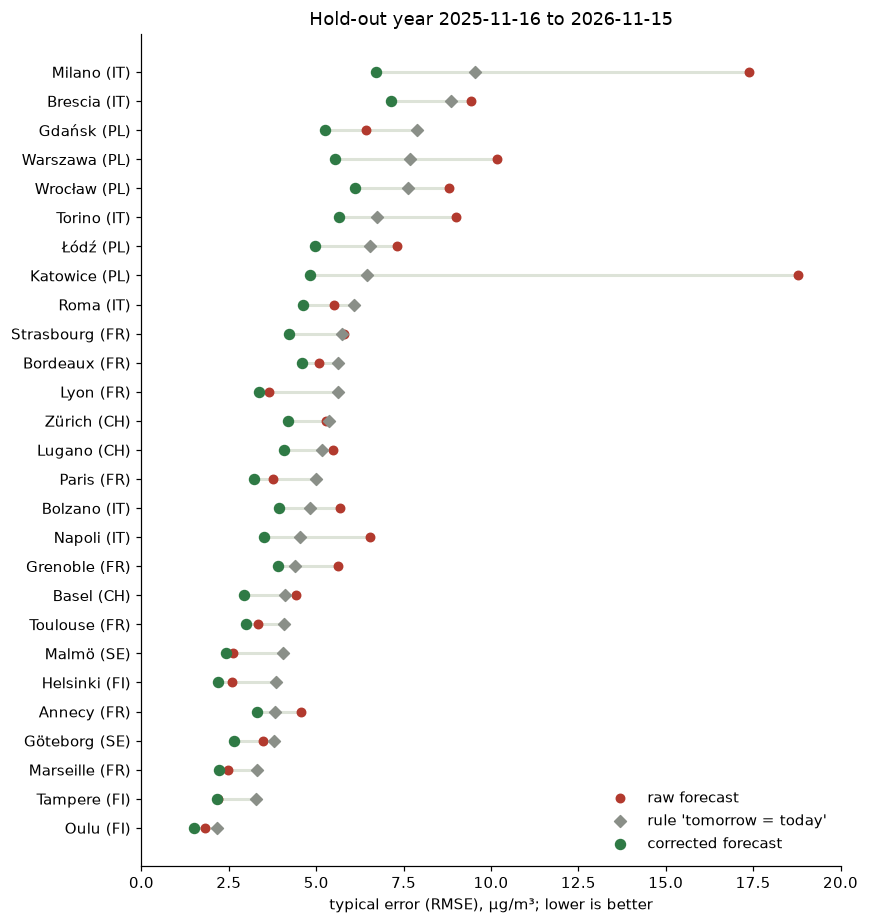

**Result on the hold-out year:** the corrected forecast beats the rule in **27 of 27 cities** and beats the raw forecast in **27 of 27**. The raw forecast beats the rule in 13. Median error: raw 5.48, rule 5.16, corrected **3.95** µg/m³.

Largest improvement: **Katowice (PL)** 18.8 → 4.8, **Milano (IT)** 17.4 → 6.7, **Warszawa (PL)** 10.2 → 5.5 µg/m³.

In [9]:
#| echo: false
h = D["summary"]["holdout"]
rows = [dict(city=f"{s['city']} ({s['country']})", raw=s["holdout"]["raw"]["rmse_fc"], cor=s["holdout"]["corrected"]["rmse_fc"],
             rule=s["holdout"]["raw"]["rmse_pers"]) for s in S if s.get("holdout", {}).get("corrected", {}).get("rmse_fc") is not None]
H = pd.DataFrame(rows)
H["gain"] = H["rule"] - H["cor"]
H = H.sort_values("rule")
fig, ax = plt.subplots(figsize=(8, 8.5))
y = np.arange(len(H))
ax.hlines(y, H[["raw", "cor", "rule"]].min(axis=1), H[["raw", "cor", "rule"]].max(axis=1), color="#dde3d8", lw=2)
ax.scatter(H["raw"], y, color="#b23a2e", s=30, label="raw forecast", zorder=3)
ax.scatter(H["rule"], y, color="#8a8f88", s=30, marker="D", label="rule 'tomorrow = today'", zorder=3)
ax.scatter(H["cor"], y, color="#2f7a45", s=42, label="corrected forecast", zorder=4)
ax.set_yticks(y); ax.set_yticklabels(H["city"])
ax.set_xlim(0, 20); ax.set_xlabel("typical error (RMSE), µg/m³; lower is better")
ax.set_title(f"Hold-out year {h['period'][0]} to {h['period'][1]}")
ax.legend(frameon=False, loc="lower right")
plt.tight_layout(); plt.show()
display(Markdown(
    f"**Result on the hold-out year:** the corrected forecast beats the rule in **{h['corrected_beats_persistence']} of "
    f"{h['stations']} cities** and beats the raw forecast in **{h['corrected_beats_raw']} of {h['stations']}**. "
    f"The raw forecast beats the rule in {h['raw_beats_persistence']}. "
    f"Median error: raw {h['median_rmse_raw']}, rule {h['median_rmse_persistence']}, corrected **{h['median_rmse_corrected']}** µg/m³."))
big = H.assign(drop=H["raw"] - H["cor"]).sort_values("drop", ascending=False).head(3)
display(Markdown("Largest improvement: " + ", ".join(f"**{r.city}** {r.raw:.1f} → {r.cor:.1f}" for r in big.itertuples()) + " µg/m³."))

Two honest notes:

- **Part of the gain comes from the last measurement.** The correction uses what the station measured the day before.
  In the live system station data arrive later, so the live version uses the measurement from two days before.
- **The hold-out year uses archived forecasts.** Their lead time is below one day. The live test of the corrected
  forecast runs from 18 November 2026 to 15 February 2027, with the same rules.

## 7. What this does not prove yet

- **Sections 2–5 are descriptive.** I wrote those rules after the archive data already existed.
  Section 6 is a test on a hold-out year, but not yet a live test.
- **The real test is running now.** Since 14 November 2026 the pipeline saves every day-ahead forecast on the day it
  is issued. The test rules were fixed before the first test day
  ([protocol A1](https://github.com/geoworldlook/air-check/blob/main/docs/evidence/A1_protokol_prognozy.md), in Polish).
  The window is 16 November 2026 to 13 February 2027 for the raw forecast and 18 November 2026 to
  15 February 2027 for the corrected one. I will report both verdicts, also if they are negative.
- **One station per city.** A station is a point and the forecast is a square of about 10 km.
- **Missing cities.** 20 of 47 candidate cities have no usable urban background station with current data in the
  EEA feeds (for example Kraków, København, Stockholm, Oslo and Bergen). The list with reasons is in the repository.
- **No health statement.** This page says nothing about health effects or legal limits.

**Data:** measurements from the European Environment Agency (Air Quality e-Reporting, reported by the national
networks). Forecast: generated using Copernicus Atmosphere Monitoring Service information (CAMS European air quality
forecasts), accessed through the Open-Meteo Air Quality API.

**Code and live panel:** [github.com/geoworldlook/air-check](https://github.com/geoworldlook/air-check) ·
[live panel](https://geoworldlook.github.io/air-check/showcase/aircheck_panel.html)